In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/images/1.jpg
/kaggle/input/images/4.jpg
/kaggle/input/images/3.jpg
/kaggle/input/images/chair.jpg
/kaggle/input/images/2.jpg


In [2]:
import torch
from transformers import AutoProcessor, LlavaForConditionalGeneration

# Load the model in half-precision
model = LlavaForConditionalGeneration.from_pretrained("llava-hf/llava-1.5-7b-hf", torch_dtype=torch.float16, device_map="auto", output_hidden_states=True)
processor = AutoProcessor.from_pretrained("llava-hf/llava-1.5-7b-hf")

2025-07-01 18:24:26.955407: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751394267.137612      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751394267.191825      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/4.18G [00:00<?, ?B/s]

... (11 outputs left out)

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

In [3]:
device = 'cuda' if torch.cuda.is_available else 'cpu'

In [4]:
from PIL import Image
image = Image.open("/kaggle/input/images/chair.jpg").convert("RGB")

ques = 'What is shown in this image?'

In [5]:
image.size

(1569, 1570)

In [6]:
conversation = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": ques},
        ],
    },
]

inputs = processor.apply_chat_template(
    conversation,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device, torch.float16)

In [7]:
# Generate
generate_ids = model.generate(**inputs, max_new_tokens=30, output_hidden_states=True, return_dict_in_generate=True) #"output"


In [8]:
sequences = generate_ids.sequences   # this is your (batch_size, seq_len) tensor
decoded = processor.batch_decode(
    sequences.tolist(),            # convert to plain Python lists of ints
    skip_special_tokens=True
)

In [9]:
print(decoded)

['USER:  \nWhat is shown in this image? ASSISTANT: The image shows a chair that has been knocked over and is now lying on the ground.']


In [10]:
from transformers import AutoTokenizer

In [11]:
tokenizer = AutoTokenizer.from_pretrained("llava-hf/llava-1.5-7b-hf")

ip_tokens = tokenizer.tokenize(ques)

In [12]:
len(tokenizer.tokenize('The image shows a chair that has been knocked over and is now lying on the ground.'))

19

In [13]:
all_hidden_states = generate_ids.hidden_states

In [14]:
len(all_hidden_states[19])

33

In [15]:
new_hidden_states = all_hidden_states[1:]

In [16]:
concatenated: tuple[torch.Tensor, ...] = tuple(
    torch.cat(token_states, dim=1)
    for token_states in zip(*new_hidden_states)
)
# check
print(len(concatenated))              # 33
print(concatenated[0].shape)          # torch.Size([1, 19, 4096])

33
torch.Size([1, 19, 4096])


In [17]:
old_hidden_states = all_hidden_states[0]

In [18]:
merged = tuple(
    torch.cat((h0, c), dim=1)
    for h0, c in zip(old_hidden_states, concatenated)
)
hidden_states = merged

In [19]:
def decode_token_with_logitlens():
    # 'text' is the generate_ids

    # a list of input tokens which is ip_tokens 
    text_tokens = ip_tokens
    
    classifier_head = model.language_model.lm_head

    decoded_intermediate_token = {}
    decoded_intermediate_logit = {}
    with torch.no_grad():
        for layer_id in range(len(hidden_states)): 
            hidden_state = hidden_states[layer_id]
            decoded_value = classifier_head(hidden_state) # [batch, seq_len, vocab_size]
            # get probabilities
            decoded_values = torch.nn.functional.softmax(decoded_value, dim=-1)
            # take max element
            argmax = torch.argmax(decoded_values, dim=-1)[0] # select first element in batch
            # decode all tokens
            decoded_token = [tokenizer.decode(el) for el in argmax]
            decoded_logit = [decoded_values[0, it, argmax[it]].item() for it in range(len(argmax))] # list of layers, per layer the sequence_length
            decoded_intermediate_token[layer_id] = decoded_token
            decoded_intermediate_logit[layer_id] = decoded_logit

    tokens = list(decoded_intermediate_token.values()) # [num_layers, seq_len]
    logits = list(decoded_intermediate_logit.values()) # [num_layers, seq_len]

    return {'text_tokens':text_tokens, 'decoded_tokens': tokens, 'decoded_logits': logits}


In [20]:
# let's test patch decode 
dict_output = decode_token_with_logitlens()
decoded_tokens = dict_output['decoded_tokens']
decoded_logits = dict_output['decoded_logits']
text_tokens = dict_output['text_tokens']
print(len(text_tokens), text_tokens)

7 ['▁What', '▁is', '▁shown', '▁in', '▁this', '▁image', '?']


In [21]:
import matplotlib.pyplot as plt

/tmp/ipykernel_19/1818443696.py:20: UserWarning: Glyph 10134 (\N{HEAVY MINUS SIGN}) missing from current font.
  plt.savefig("/kaggle/working/my_plot.png")
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10134 (\N{HEAVY MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


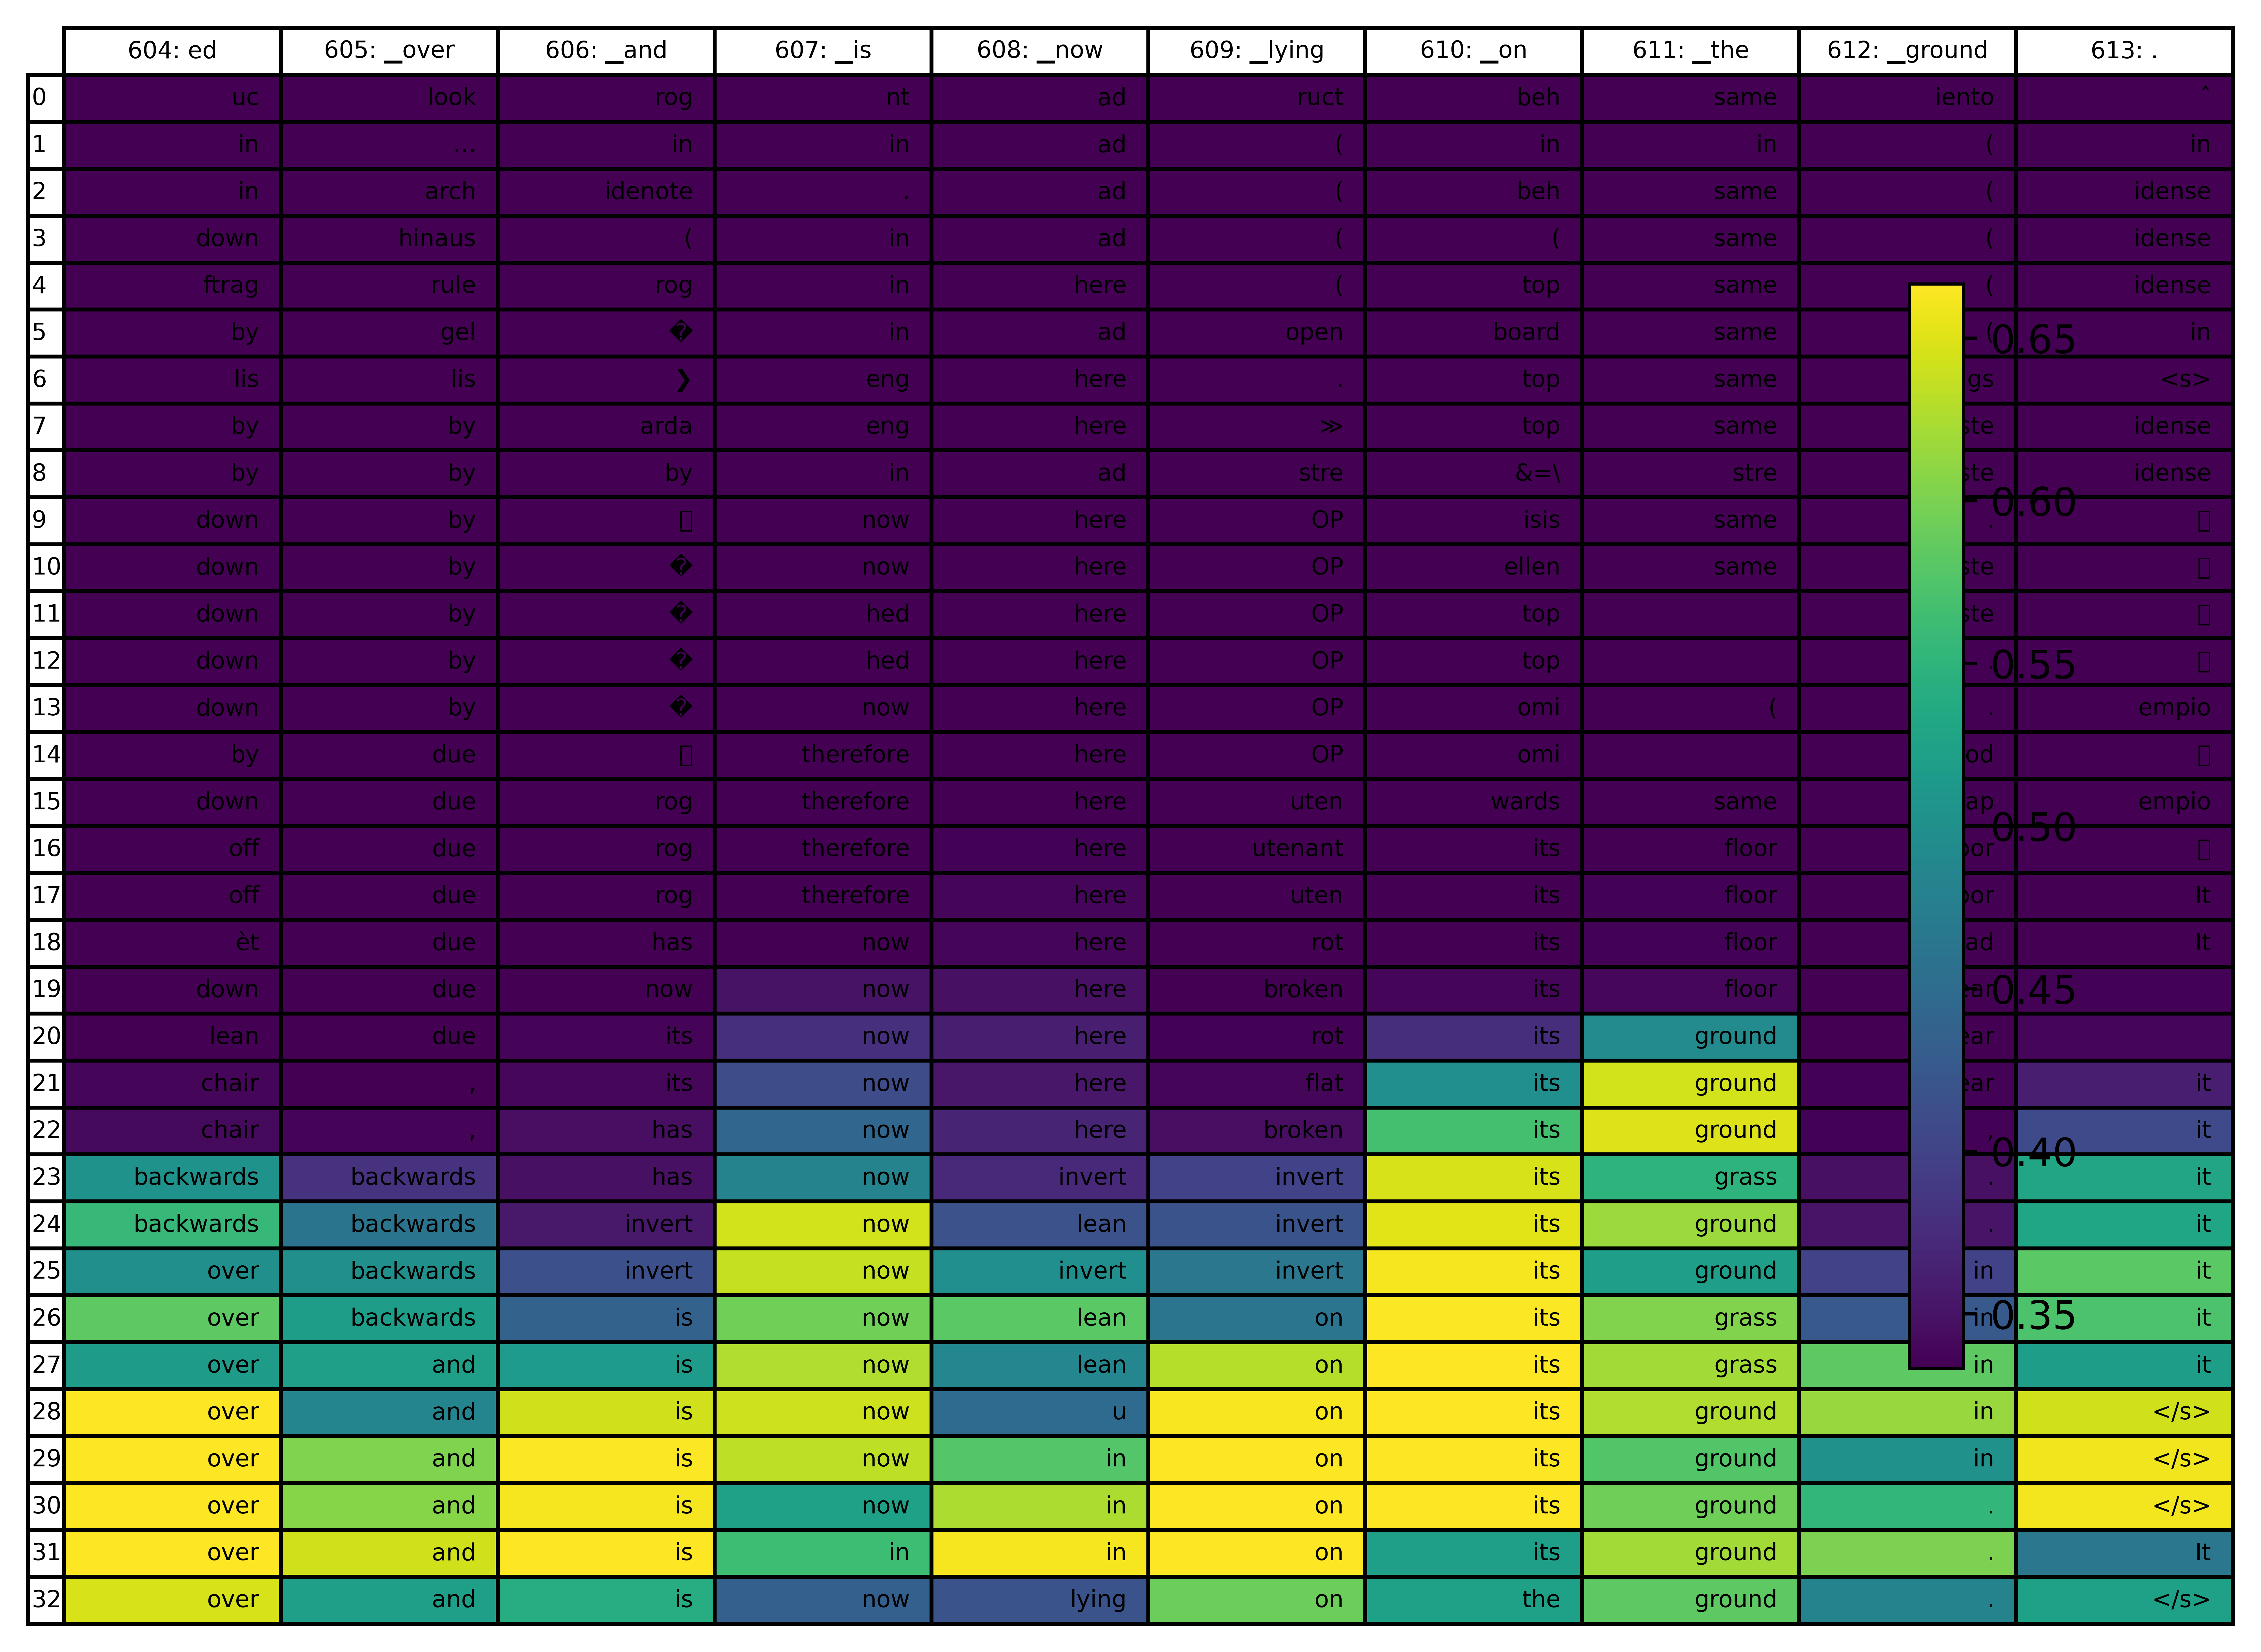

In [22]:
text_tokens2 = ['patch']*588 + text_tokens + tokenizer.tokenize('The image shows a chair that has been knocked over and is now lying on the ground.')

to_viz = (604, 614) # till 614, starting 588 are image patches
tokens_viz = [tok[to_viz[0]:to_viz[1]] for tok in decoded_tokens] # [num_layers, tokens_to_viz]
logits_viz = np.array([log[to_viz[0]:to_viz[1]] for log in decoded_logits]) # [num_layers, tokens_to_viz]
a = [it for it in range(to_viz[0],to_viz[1])]
b = [tok for tok in text_tokens2[to_viz[0]:to_viz[1]]]
col_labels = [str(a_)+': '+b_ for a_, b_ in zip(a, b)]
norm = plt.Normalize(logits_viz.min()-1, logits_viz.max()+1)
colours = plt.cm.cool(norm(logits_viz))
fig, ax = plt.subplots(figsize=(20,5), dpi=1000)
# hide axes
fig.patch.set_visible(False)
ax.axis('off')
ax.axis('tight')
img = plt.imshow(norm(logits_viz), cmap="viridis")
plt.colorbar()
img.set_visible(False)
ax.table(cellText=tokens_viz, rowLabels=[lay for lay in range(len(decoded_tokens))], colLabels=col_labels, colWidths = [0.2]*logits_viz.shape[1], loc='center', cellColours=img.to_rgba(norm(logits_viz))) 
plt.savefig("/kaggle/working/my_plot.png")
plt.show()

In [23]:
# What is shown in this image?
# The image shows a chair that has been knocked over and is now lying on the ground.